# 05 Why do some queries fail under every model?

Self-contained: this notebook downloads NFCorpus and four embedding models from the Hugging Face Hub, embeds everything, and computes every number and figure from scratch. It does not read `results/`, `cache/`, or any `silent_rag` module, so it runs on a fresh machine with only the pip packages below. Expect roughly 15-30 minutes on a laptop CPU (the corpus is embedded once per model).

**Questions**
1. Are failures shared across models more than chance?
2. What do universal failures look like? Is the "indirect judgment" explanation supported once the number of judged documents is accounted for?
3. Do they vary by split?
4. How much does switching model rescue, and how much does it break?

**Approach**
Observed vs expected failure counts under independence (Poisson-binomial, Monte-Carlo; a reference scale only), pairwise Cohen's kappa, graded-relevance comparison with Fisher / Mann-Whitney and Holm, a logistic regression adjusting the level-1 comparison for `log(n_rel)`, Wilson intervals by split, and rescue / break counts with exact McNemar tests. Two separate blind rating sheets are generated for a human audit; **no human ratings exist, so this notebook makes no claim about what raters would find.** Each inferential section has a "Why this test" note giving the estimand, the unit of independence, the assumptions and the Monte Carlo resolution.

**Scope.** NFCorpus only, the project's development set. SciFact and FiQA are held out for the final run, so this notebook deliberately does not load them.

A query "fails" under a model when none of its relevant documents is in the top 10 (recall@10 = 0). A **universal failure** fails under all four models; a **control** fails under none.

In [1]:
# Uncomment on a fresh environment.
# %pip install -q datasets sentence-transformers scikit-learn scipy pandas numpy matplotlib

In [2]:
import os
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")  # macOS: OpenMP clash between libraries; harmless elsewhere
os.environ.setdefault("OMP_NUM_THREADS", "1")

import platform
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from datasets import load_dataset
from scipy import stats
from sentence_transformers import SentenceTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import cohen_kappa_score

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 200, "display.max_columns", 30)

SEED = 0
np.random.seed(SEED)
K = 10
DEPTH = 100
SPLITS = ["train", "validation", "test"]   # the Hub qrels name is "validation", not "dev"
MAX_SEQ = 512
SAVE_AUDIT_SHEET = False  # set True to write the two audit sheets and their keys to audit_out/ (never commit: the keys hold qrel-derived data)
AUDIT_DIR = "audit_out"

NFCORPUS = dict(
    repo="BeIR/nfcorpus", revision="b5026a0e96e8a7ac4f95f482a596389289d46269",
    qrels="BeIR/nfcorpus-qrels", qrels_revision="a451b3b26d3ae1358f259c1a3a4dd61fcea35a65",
)
MODELS = {
    "multi-qa-MiniLM": dict(repo="sentence-transformers/multi-qa-MiniLM-L6-cos-v1", revision="b207367332321f8e44f96e224ef15bc607f4dbf0", query_prefix="", doc_prefix=""),
    "all-MiniLM": dict(repo="sentence-transformers/all-MiniLM-L6-v2", revision="1110a243fdf4706b3f48f1d95db1a4f5529b4d41", query_prefix="", doc_prefix=""),
    "bge-small": dict(repo="BAAI/bge-small-en-v1.5", revision="5c38ec7c405ec4b44b94cc5a9bb96e735b38267a", query_prefix="Represent this sentence for searching relevant passages: ", doc_prefix=""),
    "e5-small": dict(repo="intfloat/e5-small-v2", revision="ffb93f3bd4047442299a41ebb6fa998a38507c52", query_prefix="query: ", doc_prefix="passage: "),
}
labels = list(MODELS)
BASELINE = labels[0]

/Users/Shared/github_shared/Silent-RAG-Failures/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1016 00:48:09.162000 57094 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


## Helpers, data and clean retrieval for all four models

Data loading, encoding, exact cosine search and nDCG-free recall@10. Every labelled query with at least one relevant document is used (train, validation and test qrels; a query keeps the first split it appears in). `first_rank` is the rank of the first relevant document (101 means it is not in the top 100).

In [3]:
def doc_text(title, text):
    return f"{(title or '').strip()} {(text or '').strip()}".strip()


def load_nfcorpus():
    c = NFCORPUS
    corpus = load_dataset(c["repo"], "corpus", split="corpus", revision=c["revision"])
    queries = load_dataset(c["repo"], "queries", split="queries", revision=c["revision"])
    qtext = {str(q["_id"]): q["text"] for q in queries}
    split_of, qrels = {}, {}
    for split in SPLITS:
        for row in load_dataset(c["qrels"], split=split, revision=c["qrels_revision"]):
            q = str(row["query-id"])
            if split_of.setdefault(q, split) == split:
                qrels.setdefault(q, {})[str(row["corpus-id"])] = int(row["score"])
    doc_ids = [str(d["_id"]) for d in corpus]
    docs = [doc_text(t, x) for t, x in zip(corpus["title"], corpus["text"])]
    return doc_ids, docs, {q: qtext[q] for q in qrels}, qrels, split_of


def encode(enc, texts, batch_size=32):
    return np.ascontiguousarray(enc.encode(list(texts), batch_size=batch_size, normalize_embeddings=True,
                                           convert_to_numpy=True, show_progress_bar=False), dtype=np.float32)


def search(D, Q, depth=DEPTH):
    S = Q @ D.T
    # Stable full sort: exact score ties (the corpus contains duplicate documents) break by document index,
    # so the top-k does not depend on which search routine is used.
    return np.argsort(-S, axis=1, kind="stable")[:, :depth]


doc_ids, docs, queries, qrels, split_of = load_nfcorpus()
corpus = dict(zip(doc_ids, docs))
pos = {d: i for i, d in enumerate(doc_ids)}
qids = [q for q in queries if any(r > 0 for r in qrels[q].values())]
split = np.array([split_of[q] for q in qids])
rel = [{d for d, v in qrels[q].items() if v > 0} for q in qids]

runs = {}
for m in labels:
    spec = MODELS[m]
    enc = SentenceTransformer(spec["repo"], revision=spec["revision"], device="cpu")
    enc.max_seq_length = MAX_SEQ
    D = encode(enc, [spec["doc_prefix"] + t for t in docs])
    Q = encode(enc, [spec["query_prefix"] + queries[q] for q in qids])
    top = search(D, Q)
    ids = [[doc_ids[j] for j in row] for row in top]
    recall = np.array([len(r & set(i[:K])) / len(r) for r, i in zip(rel, ids)])
    first = np.array([min([j + 1 for j, d in enumerate(i) if d in r], default=DEPTH + 1) for r, i in zip(rel, ids)])
    runs[m] = {"enc": enc, "D": D, "Q": Q, "ids": ids, "recall": recall, "first_rank": first}
    print(m, "failing (recall@10 = 0):", int((recall == 0).sum()), "of", len(qids), flush=True)

F = np.column_stack([runs[m]["recall"] == 0 for m in labels])   # True = failed
n_fail = F.sum(1)
U, C = n_fail == 4, n_fail == 0
print(len(qids), "queries | failing under all four:", int(U.sum()), "| under none:", int(C.sum()))

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 16370.34it/s]


multi-qa-MiniLM failing (recall@10 = 0): 1070 of 3237


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 15293.59it/s]


all-MiniLM failing (recall@10 = 0): 1004 of 3237


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 16808.98it/s]


bge-small failing (recall@10 = 0): 921 of 3237


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 13970.95it/s]


e5-small failing (recall@10 = 0): 959 of 3237
3237 queries | failing under all four: 669 | under none: 1918


## 1. Are failures shared more than chance?

Under independence, each query fails under model `m` with its marginal probability `p_m`, so the number of failing models is Poisson-binomial. The table compares the expected and observed number of queries at each count (0 to 4), with a Monte-Carlo p-value from 5,000 simulated datasets for the observed number of universal failures (simulated in chunks of 500 so memory stays small). Pairwise kappa between models' failure indicators gets a bootstrap CI over queries.

**Why this test**
- **Estimand:** the excess of observed universal failures over what four models failing *independently at their marginal rates* would produce.
- **Unit of independence:** the query (simulation and kappa bootstrap).
- **Assumptions:** the null assumes every query has the same failure probability under a model, which is false: queries differ enormously in difficulty (1 to 1,363 relevant documents). **The null is therefore a straw man and its rejection is expected.** It is kept only as a reference scale. A difficulty-adjusted null is not computed here; the logistic adjustment in section 2 is the partial answer.
- **Why not the obvious alternative:** a chi-square test on the 0–4 count table would test the same straw-man null with an asymptotic approximation. Kappa is shown because it corrects pairwise agreement for marginal rates.
- **Resolution / Monte Carlo error:** p floor `1/5001 ≈ 0.0002`, reported as `p < 0.001`. The kappa CI comes from 500 query-bootstrap replicates and ignores topic clustering.

In [4]:
p = F.mean(0)
rng = np.random.default_rng(SEED)
N_SIM, CHUNK = 5000, 500
count_hist = np.zeros(5)       # summed over simulations: queries with k failing models
exp_all = np.empty(N_SIM, dtype=int)
for start in range(0, N_SIM, CHUNK):
    sim = (rng.random((CHUNK, len(qids), 4)) < p).sum(2)     # chunked: about 50 MB per chunk instead of 520 MB at once
    count_hist += np.array([(sim == k).sum() for k in range(5)])
    exp_all[start:start + CHUNK] = (sim == 4).sum(1)
expected = count_hist / N_SIM
observed = np.array([(n_fail == k).sum() for k in range(5)])
dep = pd.DataFrame({"models_failing": range(5), "observed": observed, "expected_if_independent": expected})
dep["ratio"] = dep["observed"] / dep["expected_if_independent"]
print("Monte-Carlo p for observed universal failures under independence:", (1 + (exp_all >= observed[4]).sum()) / (N_SIM + 1))
display(dep.round(2))

rows = []
for i in range(4):
    for j in range(i + 1, 4):
        k = cohen_kappa_score(F[:, i], F[:, j])
        boot = [cohen_kappa_score(F[s, i], F[s, j]) for s in (rng.integers(0, len(qids), len(qids)) for _ in range(500))]
        rows.append({"pair": f"{labels[i]} vs {labels[j]}", "kappa": k, "ci_lo": np.percentile(boot, 2.5), "ci_hi": np.percentile(boot, 97.5)})
pd.DataFrame(rows).round(3)

Monte-Carlo p for observed universal failures under independence: 0.0001999600079984003


,models_failing,observed,expected_if_independent,ratio
0,0,1918,752.28,2.55
1,1,240,1325.97,0.18
2,2,192,874.87,0.22
3,3,218,255.82,0.85
4,4,669,28.06,23.84


,pair,kappa,ci_lo,ci_hi
0,multi-qa-MiniLM vs all-MiniLM,0.760,0.736,0.786
1,multi-qa-MiniLM vs bge-small,0.704,0.677,0.730
2,multi-qa-MiniLM vs e5-small,0.717,0.690,0.742
3,all-MiniLM vs bge-small,0.742,0.716,0.766
4,all-MiniLM vs e5-small,0.745,0.720,0.770
5,bge-small vs e5-small,0.774,0.746,0.799


## 2. Relevance level, and what the failures look like

For each query: the highest relevance level among its judgments (NFCorpus uses 2 = directly cited, 1 = indirectly linked), the number of relevant documents and the query length in tokens. If universal failures are mostly queries whose best judgment is level 1, that supports the "indirect judgment" explanation. Tests: Fisher exact for "best judgment is level 1", Mann-Whitney with rank-biserial effect size for the rest, bootstrap CIs for differences. p-values are Holm-adjusted across the **three** tests in the first table.

**Manifestations are separated from explanations (second-review change).** The rank of the first relevant document and the cosine between the baseline's top-1 document and the nearest relevant document restate the outcome: a failing query has its first relevant document beyond rank 10 by definition, and when the top-1 document is itself relevant the cosine is exactly 1.0 (common among controls). They are shown in a separate descriptive table, with no test, and are no longer part of the Holm family.

**Why this test**
- **Estimand:** differences between universal failures and controls (queries failing under no model) in pre-outcome query properties.
- **Unit of independence:** the query.
- **Assumptions:** Fisher's exact test conditions on the margins and assumes independent queries. Mann-Whitney tests stochastic dominance, not a difference in means, so the rank-biserial effect size is reported next to it. Both ignore topic clustering, so the p-values are optimistic.
- **Why not the obvious alternative:** a t-test on `n_rel` (range 1 to 1,363, heavily skewed) would be driven by a few queries. Chi-square on a 2×2 table with one small cell is less exact than Fisher. Holm rather than Bonferroni: same guarantee, more power.
- **Resolution / Monte Carlo error:** exact or asymptotic p-values, no Monte Carlo floor. Bootstrap CIs use 2,000 replicates.

In [5]:
base = runs[BASELINE]
max_level = np.array([max(qrels[q].values()) for q in qids])
n_rel = np.array([len(r) for r in rel])
first_rank = base["first_rank"]
D, Q = base["D"], base["Q"]
near_miss = np.array([float(max(D[pos[d]] @ D[pos[base["ids"][i][0]]] for d in rel[i] if d in pos)) for i in range(len(qids))])
top1_is_relevant = np.array([base["ids"][i][0] in rel[i] for i in range(len(qids))])
q_tokens = np.array([len(base["enc"].tokenizer.tokenize(queries[q])) for q in qids])


def rank_biserial(a, b):
    return 2 * stats.mannwhitneyu(a, b).statistic / (len(a) * len(b)) - 1


def holm(p):
    p = np.asarray(p, float)
    order = np.argsort(p)
    out, run = np.empty(len(p)), 0.0
    for rank, i in enumerate(order):
        run = max(run, min(1.0, p[i] * (len(p) - rank)))
        out[i] = run
    return out


rows = []
level1_u, level1_c = max_level[U] == 1, max_level[C] == 1
odds, p_f = stats.fisher_exact([[level1_u.sum(), (~level1_u).sum()], [level1_c.sum(), (~level1_c).sum()]])
rng = np.random.default_rng(SEED)
bd = [level1_u[rng.integers(0, U.sum(), U.sum())].mean() - level1_c[rng.integers(0, C.sum(), C.sum())].mean() for _ in range(2000)]
rows.append({"measure": "share with best judgment = level 1", "universal_failures": level1_u.mean(), "controls": level1_c.mean(),
             "diff": level1_u.mean() - level1_c.mean(), "ci_lo": np.percentile(bd, 2.5), "ci_hi": np.percentile(bd, 97.5),
             "effect_rank_biserial": np.nan, "test": "Fisher exact", "p": p_f})
for name_, arr in (("number of relevant docs", n_rel), ("query tokens", q_tokens)):
    a, b = arr[U].astype(float), arr[C].astype(float)
    bd = [a[rng.integers(0, len(a), len(a))].mean() - b[rng.integers(0, len(b), len(b))].mean() for _ in range(2000)]
    rows.append({"measure": name_ + " (mean)", "universal_failures": a.mean(), "controls": b.mean(), "diff": a.mean() - b.mean(),
                 "ci_lo": np.percentile(bd, 2.5), "ci_hi": np.percentile(bd, 97.5), "effect_rank_biserial": rank_biserial(a, b),
                 "test": "Mann-Whitney", "p": stats.mannwhitneyu(a, b).pvalue})
chars = pd.DataFrame(rows)
chars["p_holm"] = holm(chars["p"])
chars["n_universal"], chars["n_controls"] = int(U.sum()), int(C.sum())
display(chars.round(4))

# Manifestations of failure: descriptive only, no test (they restate the outcome)
man = []
for name_, arr in (("rank of first relevant (baseline; 101 = beyond top 100)", first_rank), ("cosine: top-1 to nearest relevant", near_miss)):
    man.append({"manifestation": name_, "universal_failures_mean": arr[U].mean(), "controls_mean": arr[C].mean(),
                "universal_failures_median": np.median(arr[U]), "controls_median": np.median(arr[C])})
print("Manifestations (restate the definition of failure; not tested):")
display(pd.DataFrame(man).round(3))
print("share of queries whose baseline top-1 document is itself relevant (cosine = 1.0 by construction): controls",
      round(float(top1_is_relevant[C].mean()), 3), "| universal failures", round(float(top1_is_relevant[U].mean()), 3))

,measure,universal_failures,controls,diff,ci_lo,ci_hi,effect_rank_biserial,test,p,p_holm,n_universal,n_controls
0,share with best judgment = level 1,0.9671,0.9145,0.0526,0.0339,0.0711,NaN,Fisher exact,0.0,0.0,669,1918
1,number of relevant docs (mean),9.0538,59.4943,-50.4405,-56.0725,-44.9620,-0.6553,Mann-Whitney,0.0,0.0,669,1918
2,query tokens (mean),4.3528,5.2753,-0.9225,-1.2267,-0.6281,-0.1536,Mann-Whitney,0.0,0.0,669,1918


Manifestations (restate the definition of failure; not tested):


,manifestation,universal_failures_mean,controls_mean,universal_failures_median,controls_median
0,rank of first relevant (baseline; 101 = beyond...,85.046,1.836,101.000,1.0
1,cosine: top-1 to nearest relevant,0.348,0.869,0.351,1.0


share of queries whose baseline top-1 document is itself relevant (cosine = 1.0 by construction): controls 0.672 | universal failures 0.0


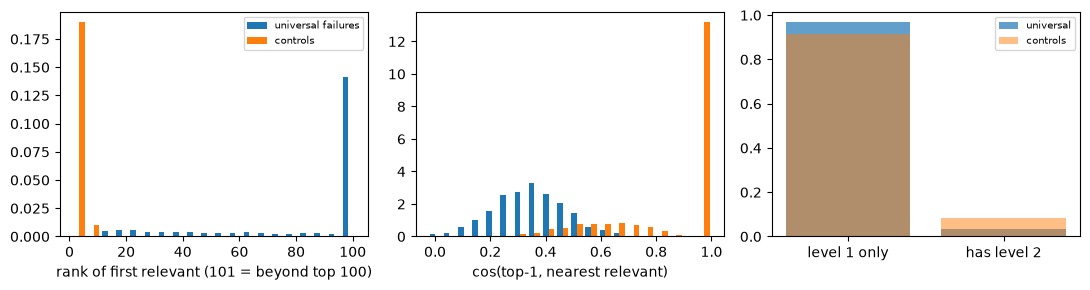

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3))
ax = axes[0]
ax.hist([np.minimum(first_rank[U], 101), np.minimum(first_rank[C], 101)], bins=np.arange(1, 105, 5), label=["universal failures", "controls"], density=True)
ax.set_xlabel("rank of first relevant (101 = beyond top 100)")
ax.legend(fontsize=7)
axes[1].hist([near_miss[U], near_miss[C]], bins=20, density=True)
axes[1].set_xlabel("cos(top-1, nearest relevant)")
axes[2].bar(["level 1 only", "has level 2"], [level1_u.mean(), 1 - level1_u.mean()], alpha=0.7, label="universal")
axes[2].bar(["level 1 only", "has level 2"], [level1_c.mean(), 1 - level1_c.mean()], alpha=0.5, label="controls")
axes[2].legend(fontsize=7)
fig.tight_layout()
plt.show()

### Is the level-1 difference explained by the number of relevant documents?

Queries with few judged documents fail more easily (recall@10 = 0 is likelier with one relevant document than with fifty), and they may also be more likely to have only level-1 judgments. A logistic regression of universal failure on `best judgment = level 1` with and without `log(n_rel)` shows whether the level-1 association survives that adjustment. It is fitted on universal failures vs controls (as in the table above) and, as a sensitivity check, on universal failures vs all other queries. Odds ratios come with 95% query-bootstrap CIs (1,000 replicates).

**Why this test**
- **Estimand:** the odds ratio of universal failure for level-1-only queries, holding `log(n_rel)` fixed.
- **Unit of independence:** the query (bootstrap). Topic clustering is ignored, so the CIs are too narrow.
- **Assumptions:** universal failure is linear in `log(n_rel)` on the log-odds scale. The comparison of the adjusted and unadjusted coefficients shows whether the adjustment matters.
- **Why not the obvious alternative:** stratifying on `n_rel` would leave thin strata (the level-1 share is 91% to 97%). The unadjusted Fisher test above cannot separate the two explanations.
- **Resolution / Monte Carlo error:** bootstrap percentile CI; replicates in which a group has no variation are skipped and counted.

In [7]:
level1 = (max_level == 1).astype(float)
log_nrel = np.log(n_rel)


def logit_coefs(X, yb):
    return LogisticRegression(penalty=None, max_iter=5000).fit(X, yb).coef_[0]


rows = []
for pop_name, mask in (("universal vs controls", U | C), ("universal vs all other queries", np.ones(len(qids), bool))):
    yb = U[mask].astype(int)
    for model_name, X in (("level-1 only", level1[mask, None]), ("level-1 + log(n_rel)", np.column_stack([level1[mask], log_nrel[mask]]))):
        est = logit_coefs(X, yb)
        rng = np.random.default_rng(SEED)
        boots, skipped = [], 0
        for _ in range(1000):
            i = rng.integers(0, len(yb), len(yb))
            if yb[i].min() == yb[i].max() or np.ptp(X[i, 0]) == 0:
                skipped += 1
                continue
            boots.append(logit_coefs(X[i], yb[i]))
        boots = np.array(boots)
        for j, term in enumerate(["level-1", "log(n_rel)"][: X.shape[1]]):
            lo, hi = np.percentile(boots[:, j], [2.5, 97.5])
            rows.append({"population": pop_name, "model": model_name, "term": term, "n": len(yb), "coef": est[j],
                         "odds_ratio": np.exp(est[j]), "or_ci_lo": np.exp(lo), "or_ci_hi": np.exp(hi), "boot_skipped": skipped})
pd.DataFrame(rows).round(3)

,population,model,term,n,coef,odds_ratio,or_ci_lo,or_ci_hi,boot_skipped
0,universal vs controls,level-1 only,level-1,2587,1.008,2.740,1.818,4.418,0
1,universal vs controls,level-1 + log(n_rel),level-1,2587,1.056,2.874,1.816,4.789,0
2,universal vs controls,level-1 + log(n_rel),log(n_rel),2587,-0.967,0.380,0.350,0.411,0
3,universal vs all other queries,level-1 only,level-1,3237,0.972,2.643,1.806,4.221,0
4,universal vs all other queries,level-1 + log(n_rel),level-1,3237,0.950,2.586,1.757,4.347,0
5,universal vs all other queries,level-1 + log(n_rel),log(n_rel),3237,-0.854,0.426,0.390,0.457,0


## 3. Does the failure share depend on the split?

If the universal-failure rate differs across train, validation and test, a test-only figure does not describe the whole dataset. Wilson 95% intervals per split and a chi-square test of homogeneity.

**Why this test**
- **Estimand:** the universal-failure rate in each official split, and whether the rates differ.
- **Unit of independence:** the query.
- **Assumptions:** binomial sampling within a split. The chi-square approximation needs expected counts ≥ 5, which every cell here meets (the smallest split has 323 queries and the rate is about 20%).
- **Why not the obvious alternative:** the Wald interval undercovers for proportions; Wilson keeps close to nominal coverage. Fisher's exact test on a 3×2 table is unnecessary at these counts.
- **Resolution / Monte Carlo error:** analytic; no Monte Carlo involved. A non-significant result here is not an equivalence claim.

In [8]:
rows = []
for s in SPLITS:
    m = split == s
    k, n = int(U[m].sum()), int(m.sum())
    ci = stats.binomtest(k, n).proportion_ci(method="wilson")
    rows.append({"split": s, "n": n, "universal_failures": k, "rate": k / n, "wilson_lo": ci.low, "wilson_hi": ci.high})
chi = stats.chi2_contingency(np.array([[r["universal_failures"], r["n"] - r["universal_failures"]] for r in rows]))
print("chi-square homogeneity across splits: chi2 =", round(chi[0], 2), "p =", round(chi[1], 4))
pd.DataFrame(rows).round(4)

chi-square homogeneity across splits: chi2 = 1.02 p = 0.6016


,split,n,universal_failures,rate,wilson_lo,wilson_hi
0,train,2590,537,0.2073,0.1922,0.2234
1,validation,324,61,0.1883,0.1495,0.2344
2,test,323,71,0.2198,0.1781,0.2681


## 4. Rescue by other models

How many of the baseline's failures does each other model fix (rescued), and how many queries that the baseline answers does it newly fail (broken)? Shown for all labelled queries and for the 323 test queries, with an exact McNemar test of "rescued = broken" on the paired failure indicators.

**Why this test**
- **Estimand:** whether switching from the baseline to a model changes the failure rate, using only the discordant queries (rescued vs broken).
- **Unit of independence:** the query (paired across the two models).
- **Assumptions:** under the null, a discordant query is equally likely to be rescued or broken, so rescued ~ Binomial(rescued + broken, 0.5). Queries are treated as independent, which ignores topic clustering.
- **Why not the obvious alternative:** comparing the two models' failure rates with an unpaired test (chi-square on two proportions) ignores that both models answered the same queries, and throws away the pairing that makes McNemar powerful. The exact binomial version avoids the continuity-correction question.
- **Resolution / Monte Carlo error:** exact, no Monte Carlo. The three contrasts per scope are Holm-adjusted.

In [9]:
rows = []
for scope, mask in (("all queries", np.ones(len(qids), bool)), ("test queries", split == "test")):
    fb = F[:, 0] & mask
    for j, l in enumerate(labels[1:], 1):
        rescued = int((fb & ~F[:, j]).sum())
        broken = int((~F[:, 0] & F[:, j] & mask).sum())
        rows.append({"scope": scope, "n_queries": int(mask.sum()), "model": l, "baseline_failures": int(fb.sum()),
                     "rescued_by_model": rescued, "newly_failing": broken,
                     "mcnemar_exact_p": stats.binomtest(rescued, rescued + broken, 0.5).pvalue})
resc = pd.DataFrame(rows)
resc["p_holm_within_scope"] = resc.groupby("scope")["mcnemar_exact_p"].transform(lambda s: holm(s.to_numpy()))
resc.round(4)

,scope,n_queries,model,baseline_failures,rescued_by_model,newly_failing,mcnemar_exact_p,p_holm_within_scope
0,all queries,3237,all-MiniLM,1070,202,136,0.0004,0.0004
1,all queries,3237,bge-small,1070,279,130,0.0000,0.0000
2,all queries,3237,e5-small,1070,253,142,0.0000,0.0000
3,test queries,323,all-MiniLM,106,18,16,0.8642,1.0000
4,test queries,323,bge-small,106,26,19,0.3713,1.0000
5,test queries,323,e5-small,106,21,17,0.6271,1.0000


## 5. Blind audit sheets

**Why two sheets (second-review change).** The earlier single sheet showed each query's retrieved top 3 next to its judged-relevant documents. For a universal failure no retrieved document can be judged-relevant, but for a control a retrieved snippet often reappeared word for word as a judged document. A rater could therefore infer the group from the text alone, which breaks the blinding (the cell after the sheets counts how often this happened). The audit is now split in two:

- **Sheet A (retrieval):** query text + the baseline's top 3 retrieved documents. Rated column: `top_doc_answers_query` (0/1).
- **Sheet B (judgments):** query text + two judged-relevant documents. Rated column: `qrel_doc_plausible` (0/1/2).

Each sheet has its own independently shuffled blind IDs and its own key, so row order and IDs cannot be used to link the two. The judged documents shown in sheet B are chosen only from judged-relevant documents **outside the baseline's top 10** whose text does not match any retrieved snippet (the corpus has 39 duplicate-document pairs). This makes the displayed sets disjoint for both groups, by construction. Only queries with at least two such documents are eligible, so every row shows the same number of documents and a blank cell cannot reveal the group; the number of excluded queries is printed. **Consequence:** for controls, raters judge relevant documents the model did *not* retrieve, the same kind of document they judge for failures. The comparison is about judgment quality, not about the retrieved hits.

**Remaining risk and protocol.** The query text appears in both sheets, so a rater who sees both could link them. Assign different raters to A and B, or have the same raters complete A first and B at least a week later. An executed assertion below checks that no query's retrieved snippets overlap its displayed judged snippets (by document ID and by text).

**Sample.** Up to 40 universal failures and 20 controls drawn at random (seed 0) from the eligible queries. **Why these sizes:** a proportion estimated from `n` ratings has a Wilson 95% half-width of at most about `0.98 / sqrt(n)`: 0.155 at n = 40, 0.22 at n = 20, 0.10 at n = 96. With 40 failures a rate of about 50% is estimated to within about ±15 points, enough to tell "mostly" from "rarely", not to resolve small differences.

**Rubric (two raters per sheet, independently):**
- Sheet A, `top_doc_answers_query` (0/1): does any of the three retrieved documents answer or substantially address the query?
- Sheet B, `qrel_doc_plausible` (0/1/2): 0 = the judged-relevant documents do not plausibly relate to the query, 1 = only tangentially or via a broad topic, 2 = directly relevant.
- `notes`: free text (for example "query is a video title", "query ambiguous").

**Planned analysis** (runs once the rating columns are filled): Cohen's kappa (with bootstrap CI) between raters for each sheet, then, on the consensus, the share of universal failures where a retrieved document is judged to answer the query (a qrels false negative) versus controls, with Fisher's exact test, and the distribution of `qrel_doc_plausible` by group.

**Output.** With `SAVE_AUDIT_SHEET = True` the sheets and keys are written to `audit_out/`. The keys contain qrel-derived data and must not be committed.

In [10]:
def snippet(doc_id, n=350):
    return corpus[doc_id][:n].replace("\n", " ")


def displayable_judged(i):
    """Judged-relevant docs outside the baseline top 10 whose text matches no retrieved top-3 snippet, best level first."""
    top10 = set(base["ids"][i][:K])
    shown_retrieved = {snippet(d) for d in base["ids"][i][:3]}
    cand = sorted(((v, d) for d, v in qrels[qids[i]].items() if v > 0 and d not in top10 and d in corpus), key=lambda x: (-x[0], x[1]))
    return [d for _, d in cand if snippet(d) not in shown_retrieved]


eligible = np.array([len(displayable_judged(i)) >= 2 for i in range(len(qids))])
print("eligible (>= 2 displayable judged docs): universal", int((U & eligible).sum()), "of", int(U.sum()),
      "| controls", int((C & eligible).sum()), "of", int(C.sum()))

rng = np.random.default_rng(SEED)
pick_u = rng.choice(np.where(U & eligible)[0], min(40, int((U & eligible).sum())), replace=False)
pick_c = rng.choice(np.where(C & eligible)[0], min(20, int((C & eligible).sum())), replace=False)
picks = np.r_[pick_u, pick_c]
order_a = np.random.default_rng([SEED, 1]).permutation(len(picks))   # independent shuffles, so row order and IDs do not link A and B
order_b = np.random.default_rng([SEED, 2]).permutation(len(picks))

rows_a, key_a, rows_b, key_b = [], [], [], []
for blind, t in enumerate(order_a, 1):
    i = picks[t]
    row = {"blind_id_a": blind, "query_text": queries[qids[i]]}
    for j, d in enumerate(base["ids"][i][:3], 1):
        row[f"retrieved_{j}"] = snippet(d)
    row.update({"rater1_top_doc_answers_query": "", "rater1_notes": "", "rater2_top_doc_answers_query": "", "rater2_notes": ""})
    rows_a.append(row)
    key_a.append({"blind_id_a": blind, "query_id": qids[i], "group": "universal_failure" if U[i] else "control", "split": split[i],
                  "shown_doc_ids": list(base["ids"][i][:3])})
for blind, t in enumerate(order_b, 1):
    i = picks[t]
    shown = displayable_judged(i)[:2]
    row = {"blind_id_b": blind, "query_text": queries[qids[i]]}
    for j, d in enumerate(shown, 1):
        row[f"judged_relevant_{j}"] = snippet(d)
    row.update({"rater1_qrel_doc_plausible": "", "rater1_notes": "", "rater2_qrel_doc_plausible": "", "rater2_notes": ""})
    rows_b.append(row)
    key_b.append({"blind_id_b": blind, "query_id": qids[i], "group": "universal_failure" if U[i] else "control", "split": split[i],
                  "max_qrel_level": int(max_level[i]), "shown_doc_ids": shown})
sheet_a, keyf_a, sheet_b, keyf_b = pd.DataFrame(rows_a), pd.DataFrame(key_a), pd.DataFrame(rows_b), pd.DataFrame(key_b)

# Leak check, linking the two sheets through their keys: no query may show the same document (by ID or by text) in both sheets.
link = keyf_a.merge(keyf_b, on=["query_id", "group"], suffixes=("_a", "_b"))
link["id_overlap"] = [len(set(a) & set(b)) for a, b in zip(link["shown_doc_ids_a"], link["shown_doc_ids_b"])]
link["text_overlap"] = [len({snippet(d) for d in a} & {snippet(d) for d in b}) for a, b in zip(link["shown_doc_ids_a"], link["shown_doc_ids_b"])]
link["n_judged_shown"] = link["shown_doc_ids_b"].map(len)
display(link.groupby("group")[["id_overlap", "text_overlap", "n_judged_shown"]].agg(["sum", "min", "max"]))
assert len(link) == len(picks), "every sampled query must appear once in each sheet"
assert link["id_overlap"].sum() == 0 and link["text_overlap"].sum() == 0, "audit leak: a retrieved snippet reappears as a judged document"
assert (link["n_judged_shown"] == 2).all(), "every sheet-B row must show the same number of judged documents"
assert not (keyf_a["query_id"].to_numpy() == keyf_b["query_id"].to_numpy()).all(), "sheets must be shuffled independently"
print("leak check passed: 0 shared documents across", len(link), "queries; blind IDs shuffled independently")

if SAVE_AUDIT_SHEET:
    os.makedirs(AUDIT_DIR, exist_ok=True)
    sheet_a.to_csv(os.path.join(AUDIT_DIR, "audit_sheet_A_retrieval.csv"), index=False)
    sheet_b.to_csv(os.path.join(AUDIT_DIR, "audit_sheet_B_judgments.csv"), index=False)
    keyf_a.to_csv(os.path.join(AUDIT_DIR, "audit_key_A.csv"), index=False)
    keyf_b.to_csv(os.path.join(AUDIT_DIR, "audit_key_B.csv"), index=False)
print(len(picks), "queries sampled:", keyf_a["group"].value_counts().to_dict())
sheet_a[["blind_id_a", "query_text", "retrieved_1"]].head(3)

eligible (>= 2 displayable judged docs): universal 535 of 669 | controls 1760 of 1918


id_overlap         text_overlap         n_judged_shown        
                         sum min max          sum min max            sum min max
group                                                                           
control                    0   0   0            0   0   0             40   2   2
universal_failure          0   0   0            0   0   0             80   2   2

leak check passed: 0 shared documents across 60 queries; blind IDs shuffled independently
60 queries sampled: {'universal_failure': 40, 'control': 20}


,blind_id_a,query_text,retrieved_1
0,1,cucumbers,"Curcumin as ""Curecumin"": from kitchen to clini..."
1,2,head trauma,Traumatic brain injuries in illustrated litera...
2,3,cytoskeleton,Cyclooxygenase inhibitory and antioxidant cyan...


In [11]:
# How often the earlier single-sheet design leaked the group: a retrieved top-3 snippet reappearing among the two
# displayed judged documents (best level first, ties by document ID), over all universal failures and controls.
def old_design_leak(i):
    shown = [d for _, d in sorted(((v, d) for d, v in qrels[qids[i]].items() if v > 0), key=lambda x: (-x[0], x[1]))[:2]]
    return bool({snippet(d) for d in base["ids"][i][:3]} & {snippet(d) for d in shown if d in corpus})


old = pd.DataFrame({"group": np.where(U, "universal_failure", np.where(C, "control", "other")),
                    "old_sheet_leaks": [old_design_leak(i) for i in range(len(qids))]})
old[old["group"] != "other"].groupby("group")["old_sheet_leaks"].agg(["sum", "count", "mean"]).round(3)

,sum,count,mean
group,,,
control,496,1918,0.259
universal_failure,0,669,0.000


In [12]:
def _kappa_ci(s, a, b, rng):
    kap = cohen_kappa_score(s[a], s[b])
    boot = [cohen_kappa_score(s[a].iloc[i], s[b].iloc[i]) for i in (rng.integers(0, len(s), len(s)) for _ in range(1000))]
    return kap, np.percentile(boot, 2.5), np.percentile(boot, 97.5)


def analyse_ratings(sheet_a_df, key_a_df, sheet_b_df, key_b_df):
    cols_a = ["rater1_top_doc_answers_query", "rater2_top_doc_answers_query"]
    cols_b = ["rater1_qrel_doc_plausible", "rater2_qrel_doc_plausible"]
    for s, cols in ((sheet_a_df, cols_a), (sheet_b_df, cols_b)):
        if (s[cols].astype(str) == "").any().any() or s[cols].isna().any().any():
            print("rating columns are not filled in yet: awaiting two independent raters per sheet. Nothing to analyse.")
            return None
    a, b = sheet_a_df.copy(), sheet_b_df.copy()
    a[cols_a], b[cols_b] = a[cols_a].astype(int), b[cols_b].astype(int)
    rng = np.random.default_rng(SEED)
    print("Cohen's kappa, sheet A (95% bootstrap CI):", tuple(round(x, 3) for x in _kappa_ci(a, *cols_a, rng)))
    print("Cohen's kappa, sheet B (95% bootstrap CI):", tuple(round(x, 3) for x in _kappa_ci(b, *cols_b, rng)))
    ma = a.merge(key_a_df, on="blind_id_a")
    ma["answers"] = ((ma[cols_a[0]] + ma[cols_a[1]]) >= 1).astype(int)   # either rater: a conservative count
    g = ma.groupby("group")["answers"].agg(["sum", "count"])
    print(g)
    tbl = [[g.loc["universal_failure", "sum"], g.loc["universal_failure", "count"] - g.loc["universal_failure", "sum"]],
           [g.loc["control", "sum"], g.loc["control", "count"] - g.loc["control", "sum"]]]
    print("Fisher exact p (retrieved document answers the query, universal vs control):", stats.fisher_exact(tbl)[1])
    mb = b.merge(key_b_df, on="blind_id_b")
    mb["plausible_mean"] = mb[cols_b].mean(1)
    print(mb.groupby("group")["plausible_mean"].describe())
    return ma, mb


# After two raters fill in the rating columns of each sheet (or of the CSVs in audit_out/, reloaded with pd.read_csv), run:
audit_result = analyse_ratings(sheet_a, keyf_a, sheet_b, keyf_b)

rating columns are not filled in yet: awaiting two independent raters per sheet. Nothing to analyse.


In [13]:
import datasets, sentence_transformers, sklearn, scipy, torch
print({"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__, "scipy": scipy.__version__,
       "sklearn": sklearn.__version__, "torch": torch.__version__, "sentence_transformers": sentence_transformers.__version__,
       "datasets": datasets.__version__, "seed": SEED, "device": "cpu", "max_seq_length": MAX_SEQ})

{'python': '3.14.6', 'numpy': '2.5.4', 'pandas': '3.0.6', 'scipy': '1.18.1', 'sklearn': '1.9.1', 'torch': '2.14.1', 'sentence_transformers': '6.1.0', 'datasets': '5.1.0', 'seed': 0, 'device': 'cpu', 'max_seq_length': 512}


## Reproducibility check against the original analysis

The original analysis saved its results as tables under `results/tables/`. This notebook recomputes everything from scratch and was compared with those tables. Where a value differs, the cause was traced and, where it was a flaw in the method rather than a rounding effect, fixed here. **Two sources of tiny differences apply to every notebook:** (1) the corpus contains 39 pairs of identical document vectors, so 29 queries have an exact score tie at rank 10/11, and which document is kept depends on the search routine (mean nDCG@10 ranges 0.29581 to 0.29590 across routines). This notebook breaks ties by document index (stable sort), which makes the top-k deterministic; the project's `pipeline.Retriever` uses FAISS, so its results can differ slightly. (2) The package versions differ from those that wrote the saved tables, so differences in the third decimal are expected.

| Quantity | Original | This notebook | Status |
|---|---|---|---|
| Queries failing under all four models / none | 669 / 1,918 | 669 / 1,918 | identical |
| Expected universal failures under independence | 28.06 | 28.06 | identical (now simulated in chunks) |
| Pairwise kappa (six pairs) | 0.705 to 0.774 | 0.704 to 0.774 | identical to 3 decimals |
| Best judgment = level 1 (universal vs controls) | 96.7% vs 91.4% | 96.7% vs 91.4% | identical |
| Mean number of relevant documents (universal vs controls) | 9.05 vs 59.49 | 9.05 vs 59.49 | identical |
| Universal-failure rate by split (train / val / test) | 20.7% / 18.8% / 22.0% | same | identical |
| Rescued / newly failing, 323 test queries | 18, 26, 21 / 16, 19, 17 | same | identical |
| Mean rank of first relevant document (universal) | 85.040 | 85.046 | +0.007% (tie-breaking) |
| **Holm family for the characteristics table** | 5 tests, including 2 restatements of the outcome | 3 tests; rank-of-first-relevant and top-1 cosine moved to an untested "manifestations" table | **changed (second review)** |
| **Audit sheet** | one sheet, retrieved and judged documents side by side | two independently shuffled sheets with disjoint documents | **changed (second review)** |

**Diagnosis.** Everything reproduces. The one numerical difference is the mean rank of the first relevant document, which moves in the fourth decimal because tied scores are broken deterministically here. The rescue table is also shown for **all 3,237 queries** (the original showed only the 323 test queries), and the Monte-Carlo p-value is reported as a floor.

**Second-review changes (this revision).**
1. *The old audit sheet was not blind.* In the single-sheet design a retrieved top-3 snippet reappeared among the two displayed judged documents for **496 of 1,918 controls (25.9%)** and for **0 of 669 universal failures** (impossible by definition). A rater could identify about a quarter of the controls from the text alone. The new design uses two sheets, shows only judged documents outside the baseline top 10, and asserts zero overlap by ID and by text: **0 shared documents across the 60 sampled queries**. Eligibility (at least two displayable judged documents) keeps 535 of 669 universal failures and 1,760 of 1,918 controls, so universal failures with a single judged document are not auditable in this design.
2. *Tautologies out of the Holm family.* Rank of the first relevant document and the top-1-to-relevant cosine are now descriptive only. 67.2% of controls have a relevant top-1 document, for which that cosine is 1.0 by construction (the control median is exactly 1.0).
3. *Level-1 adjusted for the number of judged documents.* New logistic regression (below, in Findings).
4. *McNemar tests* for rescued vs newly failing, on all queries and on the test split.
5. *Memory.* The independence simulation runs in chunks of 500 (about 50 MB each) instead of one 520 MB array; the expected counts are unchanged.
6. *"Why this test" notes* before each inferential section.

## Findings
Numbers are from a full from-scratch run (seed 0, NFCorpus, four small encoders, 3,237 queries). A query fails when none of its judged-relevant documents is in the top 10.

- **Failures are shared across models.** 669 queries fail under all four models against 28 expected if each model failed independently at its own rate (Monte-Carlo p < 0.001, floor 0.0002); pairwise kappa 0.70 to 0.77. Failing counts per model: 1,070 (baseline), 1,004, 921, 959. 1,918 queries fail under none. The independence null ignores query difficulty, so this rejection is expected and only sets a scale.
- **Universal failures differ from controls before the outcome is known:** fewer judged-relevant documents (mean 9.1 vs 59.5, rank-biserial -0.66) and shorter queries (4.4 vs 5.3 tokens, rank-biserial -0.15); both Holm-adjusted p < 0.001 in a family of three. The rank of the first relevant document (85 vs 1.8) and the top-1-to-relevant cosine (0.35 vs 0.87) restate the definition of failure and are reported only descriptively.
- **Indirect judgments survive adjustment for the number of judged documents.** 96.7% of universal failures have a best judgment of level 1 against 91.4% of controls (difference 5.3 points, CI 3.4 to 7.1; Fisher p < 0.001). In a logistic regression of universal failure (vs controls) the level-1 odds ratio is 2.74 (95% query-bootstrap CI 1.82 to 4.42) unadjusted and **2.87 (1.82 to 4.79) adjusted for log(n_rel)**; log(n_rel) has its own odds ratio of 0.38 (0.35 to 0.41) per log unit. Against all other queries the adjusted odds ratio is 2.59 (1.76 to 4.35). The association is therefore not explained by the number of judged documents, though the CIs ignore topic clustering.
- **The rate is stable across splits:** 20.7% (train), 18.8% (validation), 22.0% (test); chi-square p = 0.60.
- **Switching models fixes more than it breaks, on all queries.** Rescued vs newly failing: all-MiniLM 202 vs 136, bge-small 279 vs 130, e5-small 253 vs 142 (exact McNemar, Holm-adjusted p < 0.001 for each). On the 323 test queries the counts are 18 vs 16, 26 vs 19 and 21 vs 17 (Holm-adjusted p = 1.0 for each): the test split alone is too small to see the difference.
- **The old audit sheet leaked the group** for 25.9% of controls (496 of 1,918) through a retrieved snippet reappearing as a judged document. The replacement two-sheet design (40 universal failures, 20 controls) passes an executed zero-overlap check. No human ratings exist.

### What this supports
About one in five NFCorpus queries gets no judged-relevant document in the top 10 under all four small encoders, at a similar rate in every split. Any injected-failure effect should therefore be measured above this floor. Universal failures are more often judged only at level 1 (indirect links), and that association holds after adjusting for how many documents a query has judged.

### What this does not support
- That these are retrieval failures rather than missing relevance judgments: nothing here distinguishes them, and only the human audit can.
- That failures are shared "more than chance" in any specific sense: the independence null ignores that queries differ enormously in difficulty, so it is rejected trivially. A difficulty-adjusted null has not been computed.
- That rank-of-first-relevant and top-1 cosine *explain* failure: they restate it.
- That indirect judgments *cause* universal failure: the adjusted association is observational, its CIs treat queries as independent, and query type (video title vs question) is not modelled.
- That the audit sample represents every universal failure: 134 of 669 universal failures have fewer than two judged documents outside the top 10 and cannot enter the blind design.
- That a 20% floor exists for stronger models, other datasets, or other judgment pools; the four encoders are similar in size and training and their errors are correlated.